# Jobs 51032450 / 51072446 / 51114734 / 51151957 — seven architectures, one rung

Every stage of this programme scored one ablation at a time against the same
paired control, and read that way each row gave the same shrug: *worse than the
hub, better than the floor*. This notebook reads the whole grid as one table
instead, and the rows pile up.

**Seven complete rungs sit at `rho_50` 0.740–0.765 and `mean_solve` 0.304–0.332,
spanning 1,746,490 to 4,899,898 trainable parameters — a factor of 2.8 — across
six different interventions**: shallower depth, a narrower residual stream, a
narrower MLP, a linearised MLP, a frozen-random MLP, and no MLP at all. Removing
the entire MLP and halving the depth put the model in the same place.

The headline is scored three ways rather than asserted, because the obvious
version of it is arithmetically tilted:

1. it compares a spread of *medians* to a spread of *seeds*, and a median of
   three draws is less variable than one draw, so a **permutation test** runs on
   `mean_solve` — shuffle which rung each cell belongs to, keep the group sizes,
   20,000 times;
2. a failure to reject is also what a test with **no power** returns, so the
   identical test runs as a **positive control** on the full model's depth
   ladder, which the whole programme treats as real;
3. the control's *margin* is the finding that cuts against the headline, and it
   is reported rather than buried.

**This notebook does not beat the previous best and was not meant to.** The brief
since 2026-11-04 is the smallest or most analytically tractable architecture that
still learns direct deduction, not a stronger solver; section 5 states the
comparison against the previous best on the same eval explicitly.

Stage C (`51114734`) is scored out in section 6: its four registered rows are the
newest cells in the table above.

In [1]:
import os, subprocess, sys
sys.path.insert(0, "/home/users/hshunt/spin_gnn")
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

REPO = "/home/users/hshunt/spin_gnn"
BOOT = 2000          # the programme's scoring default; CIs here match the scorers'
SEEDS = (0, 1, 2)    # every rung in this notebook is 3 seeds unless it says otherwise

from scripts.minarch_analysis import SCAN_DEFAULT, SCAN_L6, SCAN_C, SCAN_D
from scripts.rung_collapse import BAND_LO, BAND_HI, N_PERM, PERM_SEED, describe, permutation_p
from notebooks.make_rungcollapse_deck import collect, _band, S_RHO50, S_MEAN

# Stage E (51171824) is deliberately NOT read here. Its rungs carry entirely
# default hyperparameters, so they key as plain (8,4,'no_mlp')/(12,4,'no_mlp')
# and would pool into the s* that every verdict below was already scored
# against. A new rung must never move the bar an existing verdict was measured
# with; stage E gets its own notebook when it lands.
DIRS = [SCAN_DEFAULT, SCAN_L6, SCAN_C, SCAN_D]

COMMIT = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=REPO,
                        capture_output=True, text=True).stdout.strip()
print("git commit        ", COMMIT)
print("branch            ", subprocess.run(["git", "rev-parse", "--abbrev-ref", "HEAD"],
                                           cwd=REPO, capture_output=True,
                                           text=True).stdout.strip())
print("bootstrap draws   ", BOOT)
print("permutation       ", f"{N_PERM:,} shuffles, RNG seed {PERM_SEED}")
print("band definition   ", f"rho_50 in [{BAND_LO}, {BAND_HI}] (fixed in advance, not fitted)")
print("frozen yardstick  ", f"s* = {S_RHO50} in rho_50, {S_MEAN} in mean_solve")
for d in DIRS:
    print("scan dir          ", d)

git commit         9b8e140
branch             sudoku-dd
bootstrap draws    2000
permutation        20,000 shuffles, RNG seed 0
band definition    rho_50 in [0.7, 0.82] (fixed in advance, not fitted)
frozen yardstick   s* = 0.1484 in rho_50, 0.2918 in mean_solve
scan dir           /scratch/users/hshunt/spin_gnn/sudoku_n48_minarch_2026-11-04
scan dir           /scratch/users/hshunt/spin_gnn/sudoku_n48_minarch_L6_2026-11-04
scan dir           /scratch/users/hshunt/spin_gnn/sudoku_n48_minarch_C_2026-11-04
scan dir           /scratch/users/hshunt/spin_gnn/sudoku_n48_minarch_D_2026-11-04


## 1. Provenance: the config every cell in the band was actually run with

The rungs differ from each other in exactly one field apiece. This cell reads
`config.json` off disk rather than trusting the sbatch headers, because stage
D's header turned out to have mis-estimated its own parameter count by 4%.

In [2]:
import json
from collections import defaultdict
from scripts.minarch_analysis import cell_key, load_all

cells, complete = collect(DIRS, BOOT)
desc = sorted((describe(k, ms) for k, ms in complete.items()),
              key=lambda r: (not r["readable"], r["rho50"]))
for r in desc:
    r["_cells"] = [m["mean_solve"] for m in complete[r["key"]]]
band = _band(desc)
print(f"{len(cells)} cells on disk, {len(complete)} rungs with all 3 seeds, "
      f"{len(band)} of them in the band\n")

FIELDS = ("num_layers", "d_model", "dim_feedforward", "nhead", "arch_mode", "warmup_epochs",
          "lr", "batch_size", "n_train_instances", "epochs", "shuffle_adj", "fall",
          "n_nodes", "degree", "n_colors", "seed")
print(f"{'rung':<22}" + "".join(f"{f.replace('_', ' ')[:9]:>11}" for f in FIELDS[:8]))
print("-" * 110)
for r in sorted(band, key=lambda r: r["trainable"]):
    cfg = json.load(open(os.path.join(complete[r["key"]][0]["path"], "config.json")))
    print(f"{r['label'].replace('h=4 ', '').strip():<22}"
          + "".join(f"{str(cfg.get(f)):>11}" for f in FIELDS[:8]))
print()
cfg = json.load(open(os.path.join(complete[band[0]["key"]][0]["path"], "config.json")))
print("held constant across every rung:",
      "  ".join(f"{f}={cfg.get(f)}" for f in FIELDS[8:-1]))
print("seeds per rung:", SEEDS, " (seed is the only thing that varies within a rung)")

67 cells on disk, 21 rungs with all 3 seeds, 7 of them in the band

rung                    num layer    d model  dim feedf      nhead  arch mode  warmup ep         lr  batch siz
--------------------------------------------------------------------------------------------------------------
L=6  no_mlp                     6        256       1024          4     no_mlp          0      0.001         32
L=3  full                       3        256       1024          4       full          0      0.001         32
L=6  full ff256                 6        256        256          4       full          0      0.001         32
L=4  full                       4        256       1024          4       full          0      0.001         32
L=4  linear                     4        256       1024          4     linear          0      0.001         32
L=6  rf_mlp                     6        256       1024          4     rf_mlp          0      0.001         32
L=6  linear                     6        256

## 2. The metrics table, and the three ways the headline is checked

`scripts/rung_collapse.py` prints the whole report: every complete rung ordered
by `rho_50` with the band bracketed, the band statistics, the permutation test,
the positive control, the resolution-limit caveat, and the partial rungs.

`rho_50` is the realized hint density at which the solve rate crosses 0.5 on a
14-point × 400-instance grid — **lower is better** — and it CENSORS, reported as
`>0.95`, once no bin clears 0.5. `mean_solve` is the unweighted mean over the 14
bins and never censors, which is why the permutation test runs on it: four of the
band's seven rungs have a censored seed whose `rho_50` is an inequality and
cannot be shuffled as a number.

In [3]:
out = subprocess.run([sys.executable, "-m", "scripts.rung_collapse", "--boot", str(BOOT)],
                     cwd=REPO, capture_output=True, text=True)
print(out.stdout)
if out.returncode:
    print("STDERR:", out.stderr[-2000:])

RUNG COLLAPSE: every rung with 3 seeds on disk, ordered by rho_50
  scanned 4 directories, 67 cells, 21 complete rungs (2 partial, excluded)

  rung                       rho_50   spread    mean   spread   trainable  esc
  ----------------------------------------------------------------------------
  L=12 h=4 full               0.385  0.115    0.8163   0.1530   9,638,458  3/3
  L=8  h=4 full               0.471  0.148    0.7111   0.2205   6,479,418  3/3
  L=6  h=4 full               0.592  0.012    0.5389   0.0141   4,899,898  3/3
  --- the pile-up, rho_50 in [0.7, 0.82] --------------------------------
  L=6  h=4 full ff256         0.740  0.130    0.3320   0.1588   2,535,994  3/3
  L=3  h=4 full               0.757  0.026    0.3102   0.0071   2,530,618  3/3
  L=6  h=4 rf_mlp             0.763      -    0.3104   0.2693   3,320,890  2/3
  L=6  h=4 no_mlp             0.763      -    0.3039   0.2671   1,746,490  2/3
  L=4  h=4 full               0.763      -    0.3084   0.2784   3,320,378

## 3. Capacity buys deduction only for the complete model

The same figure as page 4 of the slide deck, drawn by the deck's own code so the
two cannot drift apart. Censored rungs cannot be placed on a `rho_50` axis and
are omitted; all of them sit BELOW the band, so omitting them understates the
collapse rather than flattering it.

band:    observed spread 0.0280, p = 0.569  (7 rungs x [3, 3, 3, 3, 3, 3, 3] seeds)
control: observed spread 0.7355, p = 0.045  (6 rungs x [3, 3, 3, 3, 3, 3] seeds)
the control's separation is 26x the band's


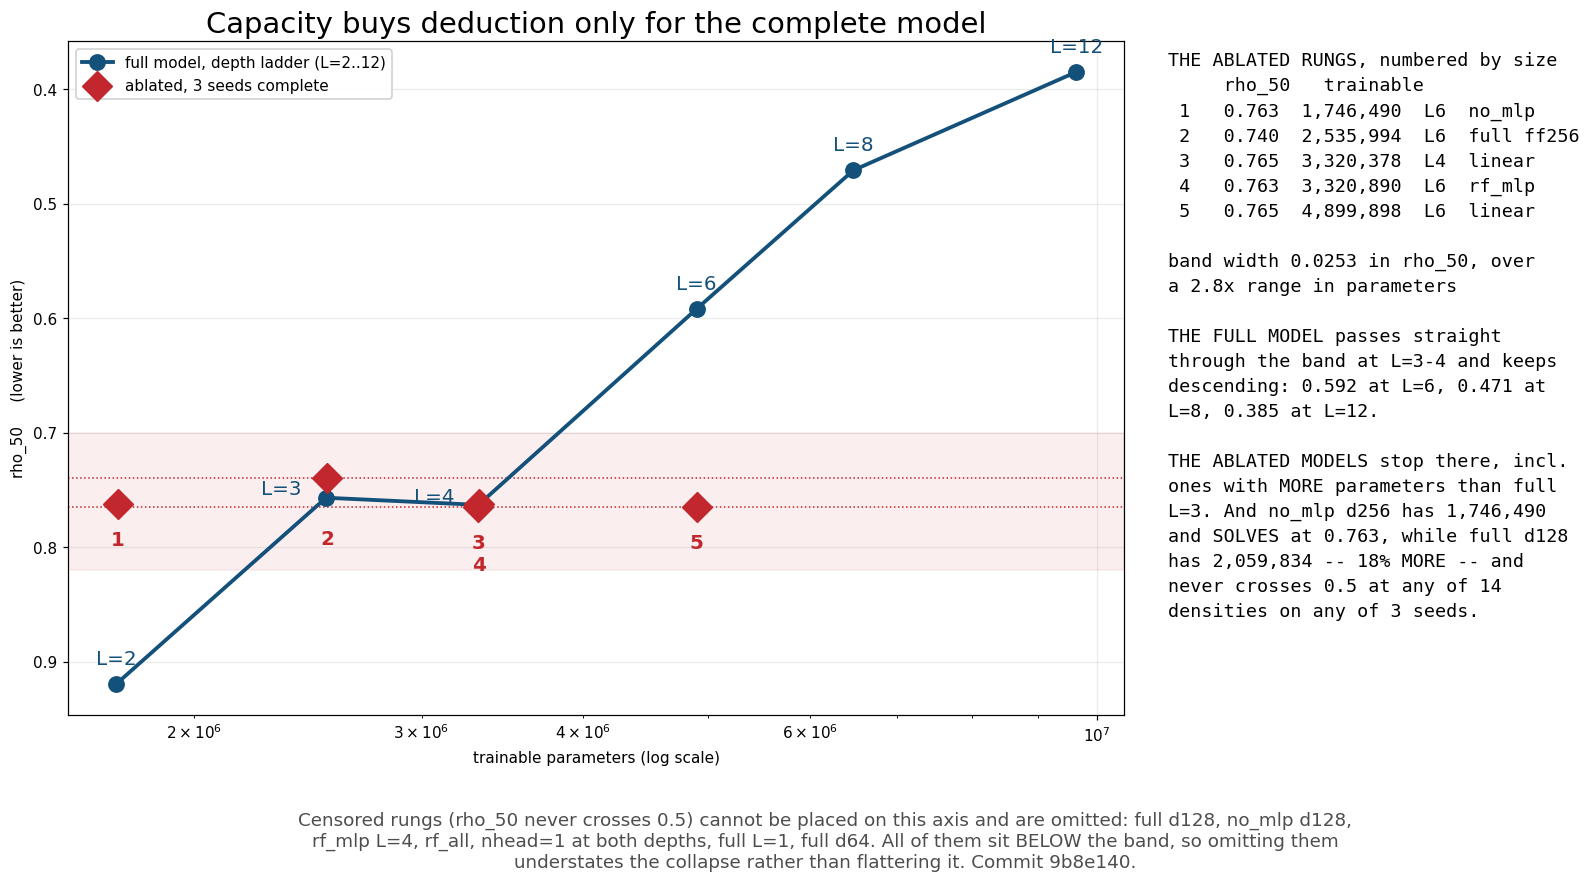

In [4]:
from notebooks.make_rungcollapse_deck import page_scatter, page_stats


class Keep:
    """A PdfAndPng stand-in that keeps the figure open for the notebook."""

    def savefig(self, fig):
        pass


obs_band, p_band, band_sizes = permutation_p({r["label"]: r["_cells"] for r in band})
ladder = {f"L={L}": [m["mean_solve"] for m in complete[(L, 4, "full")]]
          for L in (12, 8, 6, 4, 3, 2) if (L, 4, "full") in complete}
obs_ctrl, p_ctrl, ctrl_sizes = permutation_p(ladder)

page_scatter(Keep(), desc, band, COMMIT)
print(f"band:    observed spread {obs_band:.4f}, p = {p_band:.3f}  "
      f"({len(band_sizes)} rungs x {band_sizes} seeds)")
print(f"control: observed spread {obs_ctrl:.4f}, p = {p_ctrl:.3f}  "
      f"({len(ctrl_sizes)} rungs x {ctrl_sizes} seeds)")
print(f"the control's separation is {obs_ctrl / obs_band:.0f}x the band's")

## 4. The same test, run twice

Left: every seed in the band as a grey dot, the rung median in red. Right: the
three numbers that set the scale — the band's across-rung spread, the worst
*within*-rung across-seed spread, and the full-model ladder's across-rung spread.

The middle bar is 0.2918, which is identically the pooled `s*` this programme
froze as its yardstick — as it must be, since `s*` was defined as the largest
across-seed spread in the registered grid. **The entire pile-up spans one tenth
of the bar every verdict here is scored against.**

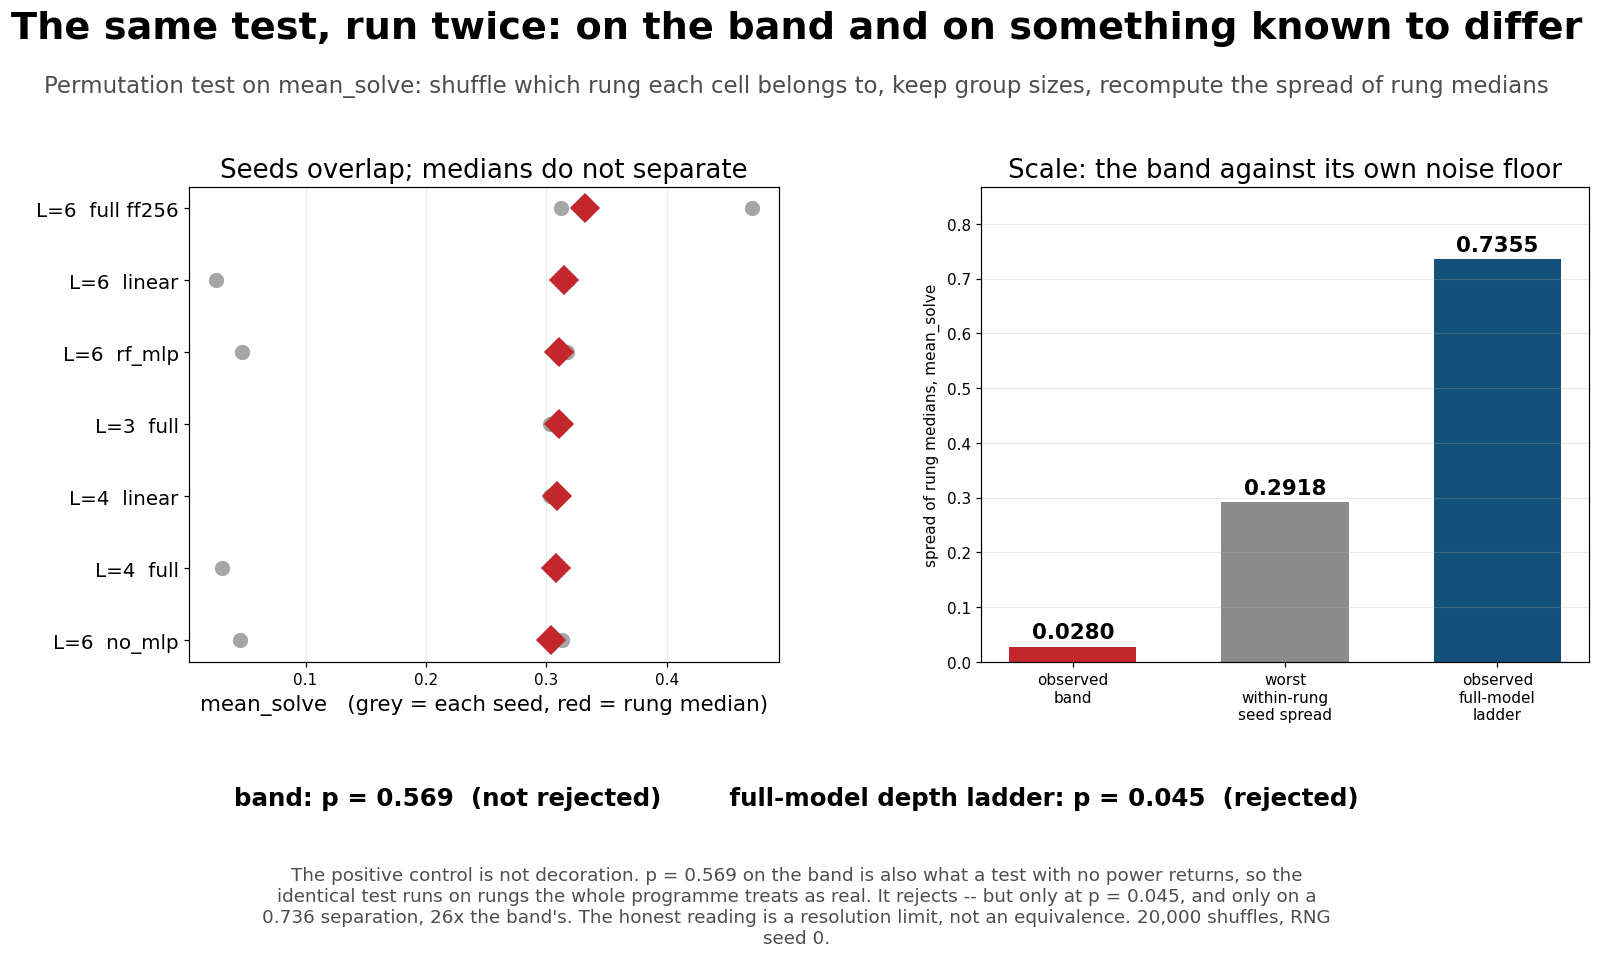

In [5]:
page_stats(Keep(), band, desc, obs_band, p_band, obs_ctrl, p_ctrl)

## 5. Comparison against the previous best on the same eval

Required by the brief and stated plainly: **nothing here is an improvement.** The
eval is unchanged — the same 14-point × 400-instance leak-free grid, the same
375k-step budget, `--shuffle-adj --fall` throughout — so the numbers are directly
comparable to every previous rung, and the full model at L=12 remains the best
solver this programme has produced.

What changed is the *question*. Since 2026-11-04 the objective is the smallest or
most analytically tractable architecture that still learns direct deduction, so
the figure of merit is the bottom row below, not the top one.

In [6]:
best = sorted((r for r in desc if r["readable"]), key=lambda r: r["rho50"])
hub = next(r for r in desc if r["key"] == (6, 4, "full"))
smallest = min(band, key=lambda r: r["trainable"])

print("BEST ON THIS EVAL -- same 14-point x 400-instance grid, same 375k-step budget")
print(f"  {'rung':<22}{'rho_50':>9}{'mean_solve':>12}{'trainable':>12}")
print("  " + "-" * 55)
for r in best[:4]:
    tag = ("   <- PREVIOUS BEST on this eval" if r is best[0] else
           "   <- the hub, paired control for every ablation" if r["key"] == hub["key"] else "")
    print(f"  {r['label'].replace('h=4 ', '').strip():<22}{r['rho50']:>9.3f}"
          f"{r['mean_solve']:>12.4f}{r['trainable']:>12,}{tag}")
print()
print("SMALLEST ARCHITECTURE IN THIS GRID THAT STILL SOLVES -- the figure of merit now")
print(f"  {smallest['label'].replace('h=4 ', '').strip():<22}{smallest['rho50']:>9.3f}"
      f"{smallest['mean_solve']:>12.4f}{smallest['trainable']:>12,}")
print()
print(f"  vs the hub: {hub['trainable'] / smallest['trainable']:.2f}x fewer trainable parameters,")
print(f"              rho_50 worse by {smallest['rho50'] - hub['rho50']:+.3f} "
      f"(s* = {S_RHO50}, so {(smallest['rho50'] - hub['rho50']) / S_RHO50:.1f} yardsticks),")
print(f"              mean_solve worse by {smallest['mean_solve'] - hub['mean_solve']:+.4f}")
print(f"  vs the best (full L=12): rho_50 worse by {smallest['rho50'] - best[0]['rho50']:+.3f} "
      f"at {best[0]['trainable'] / smallest['trainable']:.1f}x fewer parameters")
print()
print("NO IMPROVEMENT IS CLAIMED. The attention-only stack is 2.8x smaller than the hub")
print("and clearly worse at solving; what it is NOT is distinguishable from five other")
print("ablations that cost very different amounts of machinery.")

BEST ON THIS EVAL -- same 14-point x 400-instance grid, same 375k-step budget
  rung                     rho_50  mean_solve   trainable
  -------------------------------------------------------
  L=12 full                 0.385      0.8163   9,638,458   <- PREVIOUS BEST on this eval
  L=8  full                 0.471      0.7111   6,479,418
  L=6  full                 0.592      0.5389   4,899,898   <- the hub, paired control for every ablation
  L=6  full ff256           0.740      0.3320   2,535,994

SMALLEST ARCHITECTURE IN THIS GRID THAT STILL SOLVES -- the figure of merit now
  L=6  no_mlp               0.763      0.3039   1,746,490

  vs the hub: 2.81x fewer trainable parameters,
              rho_50 worse by +0.171 (s* = 0.1484, so 1.2 yardsticks),
              mean_solve worse by -0.2350
  vs the best (full L=12): rho_50 worse by +0.378 at 5.5x fewer parameters

NO IMPROVEMENT IS CLAIMED. The attention-only stack is 2.8x smaller than the hub
and clearly worse at solving; what i

## 6. Stage C (51114734), the four registered rows, 13 of 15 cells

Scored by `scripts/stagec_score.py` against the frozen `s*` and the paired
control, both fixed before stage C ran. Stage C's rungs carry a non-default
`d_model`, `ff` or `warmup`, so `rung_key()` hands them 6-tuple keys and they
stay OUT of the pooled bar stages A and B were scored against.

Two of these are worth reading as results rather than as cells:

* **P3 passes the registered rule by 0.0004 and nothing more.** Its `rho_50`
  median is 0.740 and the free/not-free threshold is 0.740. The scorer now has a
  knife-edge branch that refuses to print "quartering ff is free" for a margin
  under 10% of `s*`.
* **P4 is the registered useful result, not a failed cell.** `nhead=1` with
  warmup 5 escapes the plateau 0/3, exactly as stage B's `nhead=1` at warmup 0
  did. Two independent optimizer settings failing the same way is what licenses
  writing that verdict as a property of having one head rather than of the
  schedule.

In [7]:
out = subprocess.run([sys.executable, "-m", "scripts.stagec_score", "--boot", str(BOOT)],
                     cwd=REPO, capture_output=True, text=True)
print(out.stdout)
if out.returncode:
    print("STDERR:", out.stderr[-2000:])

STAGE C (51114734), scored against its own sbatch header
  bar in force at submission: s* = 0.1484 rho_50, 0.2918 mean_solve
  paired control  L=6  h=4 full  rho_50 0.592  mean_solve 0.5389  trainable 4,899,898
  a removal is 'free' iff rho_50 stays at or below 0.740

=== P1 -- width 256->128 ===
  3/3 seeds on disk, 0/3 crossed 0.5
  rho_50 median CENSORED   (hub 0.592)
  mean_solve median 0.0273 [spread 0.0036]   (hub 0.5389)
  trainable 2,059,834   (hub 4,899,898)
  plateau escapes 2/3   train NLL 1.623/1.649/1.621
  >>> FALSIFIED by its own registered falsifier, which reads 'gap > s*, or any
      seed censored while all three hub seeds solved'. 3 of 3 seeds never
      crossed 0.5 at any of the 14 hint densities, and all three hub seeds did.
      Halving the residual stream is NOT free: the width is itself load-bearing
      at N=48 and the minimal architecture is bounded below by it.
      AND IT IS NOT A TRAINABILITY ARTEFACT -- 2 of 3 seeds got below finding
      44's plateau

## 7. What this does not show, and what is running

The grid above cannot distinguish two readings, and the reason is structural
rather than statistical:

* **(A) BARRIER** — 0.76 is a floor that any *incomplete* architecture hits
  however much capacity it is given back, and the full model passes through it at
  L=3–4 and keeps descending only because it is complete. That would make the MLP
  load-bearing **in kind**, which is the strongest statement this programme has
  been able to make about any component.
* **(B) CAPACITY** — the ablations merely happened to cost about the same at this
  budget.

**Every ablated rung in the table was run at AT MOST the hub's depth**, so no
ablated model has ever been handed more of a resource than the model it is being
compared against. Two jobs fix that, one per axis:

| job | arm | rungs | registered falsifier of (A) |
|---|---|---|---|
| `51151957` stage D | width | `full` d192; **`no_mlp` d384** (3,799,354 trainable) | D2 crossing below 0.740 |
| `51171824` stage E | depth | `no_mlp` **L=8** (2,274,874) and **L=12** (3,331,642) | either rung below 0.740 on ≥2 of 3 crossing seeds, no partial credit |

Stage E's header is on record, written before stage D's D2 had a single completed
cell, backing **D2's falsifier over D2's own prediction**: under the barrier
reading width is not the currency either.

**The named way this produces nothing is trainability, not capacity.**
Attention-only escapes the 1.64 plateau 2/3 at L=6 and 0/3 at L=4, so a *deeper*
attention-only stack failing to escape is the expected failure mode and will be
written as "did not train in 375k steps", never as evidence for the barrier. The
budget is deliberately not raised to compensate, because a rung trained on a
different budget cannot be compared to the ladder it is read against; a
longer-budget rerun is a follow-up cell, not a fix to this one.